           date  yield_2y
6466 2026-11-13      3.37
6467 2026-11-16      3.30
6468 2026-11-17      3.30
6469 2026-11-18      3.30
6470 2026-11-19      3.30


<Axes: title={'center': 'Canada 2-Year Yield'}, xlabel='date'>

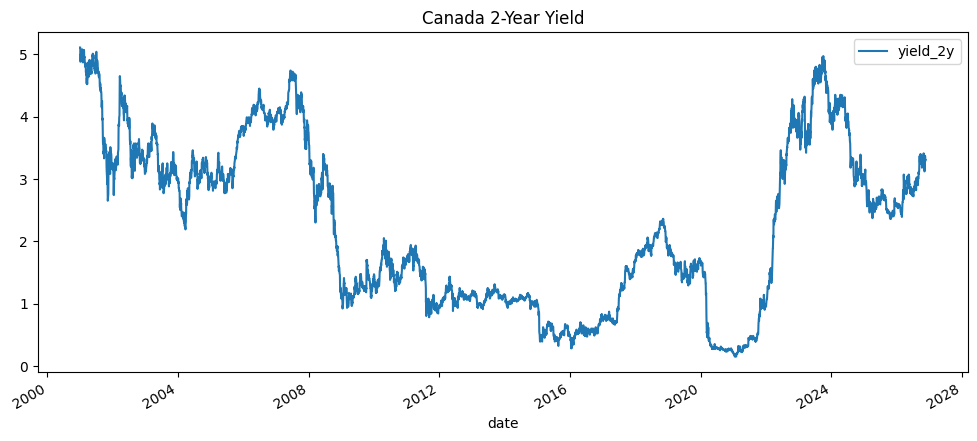

In [19]:
import requests
import pandas as pd

url = "https://www.bankofcanada.ca/valet/observations/BD.CDN.2YR.DQ.YLD/json?start_date=2000-01-01"
response = requests.get(url)
data = response.json()

rows = []
for obs in data["observations"]:
    if "BD.CDN.2YR.DQ.YLD" in obs:
        rows.append({
            "date": obs["d"],
            "yield_2y": float(obs["BD.CDN.2YR.DQ.YLD"]["v"])
        })

df = pd.DataFrame(rows)
df["date"] = pd.to_datetime(df["date"])

print(df.tail())
df.plot(x="date", y="yield_2y", title="Canada 2-Year Yield", figsize=(12, 5))

In [20]:
df.to_csv("boc_2y_yield.csv", index=False)

In [21]:
!pip install trafilatura -q

In [22]:
import requests, re, time
from bs4 import BeautifulSoup
from urllib.parse import urljoin

headers = {"User-Agent": "Mozilla/5.0 (student research project)"}
links = {}

for page in range(1, 30):
    url = f"https://www.bankofcanada.ca/utility/key-interest-rate/page/{page}/"
    html = requests.get(url, headers=headers).text
    soup = BeautifulSoup(html, "html.parser")

    for a in soup.find_all("a", href=True):
        href = urljoin(url, a["href"])
        title = a.get_text(strip=True)
        if re.search(r"/\d{4}/\d{2}/[a-z]", href) and "rate" in title.lower() and "schedule" not in title.lower():
            links[href] = title

    print(f"Page {page}: {len(links)} statements so far")
    time.sleep(1)

Page 1: 7 statements so far
Page 2: 13 statements so far
Page 3: 20 statements so far
Page 4: 27 statements so far
Page 5: 34 statements so far
Page 6: 41 statements so far
Page 7: 47 statements so far
Page 8: 53 statements so far
Page 9: 60 statements so far
Page 10: 67 statements so far
Page 11: 73 statements so far
Page 12: 80 statements so far
Page 13: 87 statements so far
Page 14: 94 statements so far
Page 15: 103 statements so far
Page 16: 112 statements so far
Page 17: 121 statements so far
Page 18: 130 statements so far
Page 19: 138 statements so far
Page 20: 147 statements so far
Page 21: 156 statements so far
Page 22: 165 statements so far
Page 23: 174 statements so far
Page 24: 183 statements so far
Page 25: 192 statements so far
Page 26: 201 statements so far
Page 27: 210 statements so far
Page 28: 220 statements so far
Page 29: 226 statements so far


In [23]:
import trafilatura
import pandas as pd

statements = []
for i, (url, title) in enumerate(links.items()):
    html = requests.get(url, headers=headers).text
    text = trafilatura.extract(html)
    meta = trafilatura.extract_metadata(html)
    statements.append({
        "url": url,
        "title": title,
        "date": meta.date if meta else None,
        "text": text
    })
    if i % 20 == 0:
        print(f"{i}/{len(links)} done")
    time.sleep(1)

df_s = pd.DataFrame(statements)
df_s.to_csv("boc_statements.csv", index=False)
print(df_s.shape)

0/226 done
20/226 done
40/226 done
60/226 done
80/226 done
100/226 done
120/226 done
140/226 done
160/226 done
180/226 done
200/226 done
220/226 done
(226, 4)


In [24]:
df_s["date"] = pd.to_datetime(df_s["date"], errors="coerce")
df_s["url_month"] = df_s["url"].str.extract(r"/(\d{4}/\d{2})/")[0]
mismatch = df_s[df_s["date"].dt.strftime("%Y/%m") != df_s["url_month"]]

print("Total statements:", len(df_s))
print("Date mismatches:", len(mismatch))
print("Missing text:", df_s["text"].isna().sum())
print()
print(df_s.loc[0, "title"])
print(df_s.loc[0, "text"][:800])

Total statements: 226
Date mismatches: 0
Missing text: 0

Bank of Canada raises the policy rate by 25 basis points to 2½%
Bank of Canada raises the policy rate by 25 basis points to 2½%
The Bank of Canada today increased its target for the overnight rate by 25 basis points to 2.5%, with the Bank Rate at 2.75% and the deposit rate at 2.45%.
Since the July Monetary Policy Report, global economic activity has remained resilient, despite higher energy prices. In the United States, the economy continues to grow at a robust pace, supported by consumer spending and AI-related investment. Growth in the euro area has been resilient and broad-based. After slowing in the second quarter, Chinese growth rebounded in the third quarter, owing to strength in exports and a pickup in fiscal spending. With persistently elevated oil prices and refinery margins, inflation has risen in most countries.
Given the ongoing resilience 


In [25]:
df_s = df_s.sort_values("date").reset_index(drop=True)
df_s["words"] = df_s["text"].str.split().str.len()

print("Date range:", df_s["date"].min().date(), "to", df_s["date"].max().date())
print()
print(df_s.groupby(df_s["date"].dt.year).size().to_string())
print()
print(df_s["words"].describe())

Date range: 1997-06-26 to 2026-10-28

date
1997    4
1998    5
1999    3
2000    6
2001    9
2002    8
2003    8
2004    8
2005    8
2006    8
2007    8
2008    8
2009    8
2010    8
2011    8
2012    8
2013    8
2014    8
2015    8
2016    8
2017    8
2018    8
2019    8
2020    8
2021    8
2022    8
2023    8
2024    8
2025    8
2026    7

count     226.000000
mean      494.955752
std       142.563102
min       250.000000
25%       394.250000
50%       474.000000
75%       586.750000
max      1408.000000
Name: words, dtype: float64


In [26]:
!pip install anthropic -q

import anthropic, json
from google.colab import userdata

client = anthropic.Anthropic(api_key=userdata.get("ANTHROPIC_API_KEY"))

In [33]:
RUBRIC = """You are a fixed-income analyst scoring a Bank of Canada interest rate statement.

Judge ONLY the text below. Do not use any knowledge of what the Bank did later or how markets reacted.

Score each dimension from -5 to +5 (whole numbers). Negative = dovish (toward lower rates), positive = hawkish (toward higher rates).
Anchors for "overall":
  +5 = very large hike AND clear signal of more hikes to come
  +3 = standard hike with a tightening bias
  +1 = hold or small move, leaning hawkish
   0 = balanced, no clear lean
  -1 = hold or small move, leaning dovish
  -3 = standard cut with an easing bias
  -5 = emergency or very large cut AND clear signal of more easing
Use the full range. Distinguish between statements of similar direction based on intensity and conviction.

Dimensions:
- rate_path: signals about future rate moves
- inflation: how worried the Bank sounds about inflation
- growth: how strong the Bank sees the economy (strong = hawkish)
- overall: your overall hawk/dove score

Return ONLY valid JSON in this exact format:
{"rate_path": 0, "inflation": 0, "growth": 0, "overall": 0, "reason": "one sentence"}"""

def score_statement(text):
    response = client.messages.create(
        model="claude-haiku-5-5",
        max_tokens=2000,
        messages=[{"role": "user", "content": RUBRIC + "\n\nSTATEMENT:\n" + text}]
    )
    raw = "".join(block.text for block in response.content if block.type == "text")
    return json.loads(raw[raw.find("{"): raw.rfind("}") + 1])

In [34]:
hike = df_s[df_s["date"] == "2022-07-13"].iloc[0]
latest = df_s.iloc[-1]

for row in [hike, latest]:
    print(row["date"].date(), "|", row["title"])
    print(score_statement(row["text"]))
    print()

2022-07-13 | Bank of Canada increases policy interest rate by 100 basis points, continues quantitative tightening
{'rate_path': 4, 'inflation': 5, 'growth': 4, 'overall': 5, 'reason': "A 100bp front-loaded hike, explicit statement that rates will need to rise further, inflation described as high, broadening and entrenching, and an economy 'clearly in excess demand' make this a very hawkish statement, tempered only slightly by the pace of future increases being left data-dependent."}

2026-10-28 | Bank of Canada raises the policy rate by 25 basis points to 2½%
{'rate_path': 3, 'inflation': 4, 'growth': 2, 'overall': 3, 'reason': "A 25bp hike driven by inflation that is higher and more persistent than expected, with CPI forecast to reach about 3.5% and cost pass-through rising, plus explicit openness to further hikes tempered by a 'proceed carefully' caveat, makes this a standard hike with a moderate tightening bias."}



In [35]:
import time

results = []
for i, row in df_s.iterrows():
    try:
        s = score_statement(row["text"])
        s["date"] = row["date"]
        s["title"] = row["title"]
        results.append(s)
    except Exception as e:
        print("Error on", row["date"].date(), "-", e)

    if i % 10 == 0:
        print(f"{i}/{len(df_s)} scored")
        pd.DataFrame(results).to_csv("scores_run1.csv", index=False)

scores = pd.DataFrame(results)
scores.to_csv("scores_run1.csv", index=False)
print("Done:", len(scores), "scored")

0/226 scored
10/226 scored
20/226 scored
30/226 scored
40/226 scored
50/226 scored
60/226 scored
70/226 scored
80/226 scored
90/226 scored
100/226 scored
110/226 scored
120/226 scored
130/226 scored
140/226 scored
150/226 scored
160/226 scored
170/226 scored
180/226 scored
190/226 scored
200/226 scored
210/226 scored
220/226 scored
Done: 226 scored


In [36]:
import requests
import pandas as pd

def get_series(code):
    url = f"https://www.bankofcanada.ca/valet/observations/{code}/json?start_date=1995-01-01"
    data = requests.get(url).json()
    rows = [{"date": o["d"], "value": float(o[code]["v"])}
            for o in data["observations"]
            if code in o and o[code].get("v") not in (None, "")]
    s = pd.DataFrame(rows)
    s["date"] = pd.to_datetime(s["date"])
    return s.set_index("date")["value"].sort_index()

y2 = get_series("BD.CDN.2YR.DQ.YLD")
y5 = get_series("BD.CDN.5YR.DQ.YLD")
policy = get_series("V39079")

d2 = (y2.diff() * 100).rename("d2_bp")
d5 = (y5.diff() * 100).rename("d5_bp")

print("2Y from", y2.index.min().date(), "| 5Y from", y5.index.min().date(), "| Policy rate from", policy.index.min().date())

2Y from 2001-01-02 | 5Y from 2001-01-02 | Policy rate from 2009-04-21


In [39]:
import re

scores = pd.read_csv("scores_run1.csv")
scores["date"] = pd.to_datetime(scores["date"]).dt.normalize()
scores = scores.merge(df_s[["date", "text"]], on="date", how="left")
scores = scores.sort_values("date").reset_index(drop=True)

FRACS = {"1/4": .25, "1/2": .5, "3/4": .75, "¼": .25, "½": .5, "¾": .75}
NUM = r"(\d+(?:\.\d+)?)?\s?(1/4|1/2|3/4|¼|½|¾)?"
PATTERN = r"(?:overnight rate|policy rate|policy interest rate)[^.]*?\b(?:to|at)\s+" + NUM + r"\s*(?:%|per\s?cent)"

def parse_rate(text):
    match = re.search(PATTERN, str(text)[:800], flags=re.IGNORECASE)
    if not match or not (match.group(1) or match.group(2)):
        return None
    whole = float(match.group(1)) if match.group(1) else 0
    frac = FRACS.get(match.group(2), 0) if match.group(2) else 0
    return whole + frac

scores["rate_level"] = scores["text"].apply(parse_rate)
scores["rate_chg_bp"] = scores["rate_level"].diff() * 100

# Tone changes
scores["overall_chg"] = scores["overall"].diff()
scores["path_chg"] = scores["rate_path"].diff()

# Join yield moves
m = scores.merge(d2, left_on="date", right_index=True, how="left")
m = m.merge(d5, left_on="date", right_index=True, how="left")

# --- Checks ---
print("Couldn't parse a rate:", m["rate_level"].isna().sum())
print(m[m["rate_level"].isna()][["date", "title"]].to_string())
print()

m["official"] = m["date"].apply(lambda d: policy.asof(d + pd.Timedelta(days=1)))
overlap = m.dropna(subset=["official", "rate_level"])
disagree = overlap[(overlap["official"] - overlap["rate_level"]).abs() > 0.001]
print(f"2009+ check: {len(overlap)} statements compared, {len(disagree)} disagree")
print(disagree[["date", "rate_level", "official", "title"]].to_string())

m.drop(columns=["text"]).to_csv("master.csv", index=False)
print()
print("Rows:", len(m), "| Missing 2Y move:", m["d2_bp"].isna().sum())
print("Missing 2Y dates:", m[m["d2_bp"].isna()]["date"].dt.date.tolist())

Couldn't parse a rate: 30
          date                                                                                                                                      title
0   1997-06-26                                                                                                 Bank Rate Raised 1/4 of a Percentage Point
1   1997-10-01                                                                                                     Bank Rate Raised by ¼ Percentage Point
2   1997-11-25                                                                 Bank Rate Raised in Response to Persistent Weakness in the Canadian Dollar
3   1997-12-12                                                                                                         Bank Rate Raised to 4 1/2 Per Cent
4   1998-01-30                                                                                                             Bank Rate Raised to 5 Per Cent
6   1998-09-29                                    

In [41]:
# 1. Keep 2001 onward
m = m[m["date"] >= "2001-01-01"].copy().reset_index(drop=True)

# 2. Parse the rate from the title as a backup
TITLE_PATTERN = r"\b(?:to|at)\s+" + NUM + r"\s*(?:%|per\s?cent)"
def parse_title(title):
    match = re.search(TITLE_PATTERN, str(title), flags=re.IGNORECASE)
    if not match or not (match.group(1) or match.group(2)):
        return None
    whole = float(match.group(1)) if match.group(1) else 0
    frac = FRACS.get(match.group(2), 0) if match.group(2) else 0
    return whole + frac

m["title_rate"] = m["title"].apply(parse_title)

# 3. Best available rate: official → title → text
m["rate_final"] = m["official"].fillna(m["title_rate"]).fillna(m["rate_level"])
m["rate_chg_bp"] = m["rate_final"].diff() * 100

# --- Check A: anything still missing? ---
print("Still missing a rate:", m["rate_final"].isna().sum())
print(m[m["rate_final"].isna()][["date", "title"]].to_string())
print()

# --- Check B: does the direction of the move match the headline? ---
def headline_direction(t):
    t = t.lower()
    if re.search(r"raise|increase", t): return 1
    if re.search(r"lower|reduce|cut", t): return -1
    if re.search(r"keep|maintain|hold|held", t): return 0
    return None

m["headline_dir"] = m["title"].apply(headline_direction)
m["data_dir"] = m["rate_chg_bp"].apply(lambda x: None if pd.isna(x) else (1 if x > 0 else -1 if x < 0 else 0))
bad = m[m["headline_dir"].notna() & m["data_dir"].notna() & (m["headline_dir"] != m["data_dir"])]
print("Direction mismatches:", len(bad))
print(bad[["date", "rate_chg_bp", "title"]].to_string())

m.drop(columns=["text"]).to_csv("master.csv", index=False)
print()
print("Final rows:", len(m), "| Missing 2Y move:", m["d2_bp"].isna().sum())

Still missing a rate: 0
Empty DataFrame
Columns: [date, title]
Index: []

Direction mismatches: 1
          date  rate_chg_bp                                                                             title
155 2020-04-15       -100.0  Bank of Canada maintains overnight rate target and unveils new market operations

Final rows: 208 | Missing 2Y move: 0


In [43]:
# 1. What's in the data around March 2020?
print(m[m["date"].between("2020-01-01", "2020-06-30")][["date", "rate_chg_bp", "title"]].to_string())
print()

# 2. Any suspiciously large moves? (could mean a missing statement before them)
big = m[m["rate_chg_bp"].abs() > 50][["date", "rate_chg_bp", "title"]]
print("Moves bigger than 50bp:")
print(big.to_string())

          date  rate_chg_bp                                                                                                                       title
153 2020-01-22          0.0                                                               Bank of Canada maintains overnight rate target at 1 ¾ percent
154 2020-03-04        -50.0                                                                  Bank of Canada lowers overnight rate target to 1 ¼ percent
155 2020-04-15       -100.0                                            Bank of Canada maintains overnight rate target and unveils new market operations
156 2020-06-03          0.0  Bank of Canada maintains target for the overnight rate, scales back some market operations as financial conditions improve

Moves bigger than 50bp:
          date  rate_chg_bp                                                                                                 title
7   2001-10-23        -75.0              Bank of Canada lowers key policy interest ra

In [44]:
headers = {"User-Agent": "Mozilla/5.0 (student research project)"}

missing = [
    ("2008-10-08", "https://www.bankofcanada.ca/2008/10/central-banks-announce-coordinated-interest-rate-reductions/", 2.50),
    ("2020-03-13", "https://www.bankofcanada.ca/2020/03/bank-of-canada-lowers-overnight-rate-target-to-%c2%be-percent/", 0.75),
    ("2020-03-27", "https://www.bankofcanada.ca/2020/03/press-release-2020-03-27/", 0.25),
]

new_rows = []
for date, url, rate in missing:
    html = requests.get(url, headers=headers).text
    text = trafilatura.extract(html)
    if not text:
        print("Couldn't get text for", date)
        continue
    meta = trafilatura.extract_metadata(html)
    s = score_statement(text)
    s.update({"date": pd.Timestamp(date),
              "title": meta.title if meta else url,
              "text": text,
              "rate_final": rate})
    new_rows.append(s)
    print(date, "|", s["title"], "| words:", len(text.split()), "| overall:", s["overall"], "| path:", s["rate_path"])

pd.DataFrame(new_rows).drop(columns=["text"]).to_csv("scores_added.csv", index=False)

# Rebuild the master table with the new rows
keep = ["date", "title", "text", "rate_path", "inflation", "growth", "overall", "reason", "rate_final"]
base = pd.concat([m[keep], pd.DataFrame(new_rows)[keep]], ignore_index=True)
base = base.sort_values("date").reset_index(drop=True)

base["rate_chg_bp"] = base["rate_final"].diff() * 100
base["overall_chg"] = base["overall"].diff()
base["path_chg"] = base["rate_path"].diff()

m = base.merge(d2, left_on="date", right_index=True, how="left")
m = m.merge(d5, left_on="date", right_index=True, how="left")
m.drop(columns=["text"]).to_csv("master.csv", index=False)

# --- Re-check ---
print()
print("Rows:", len(m), "| Missing 2Y move:", m["d2_bp"].isna().sum())
print()
print(m[m["date"].between("2008-09-01", "2008-12-31") | m["date"].between("2020-01-01", "2020-06-30")][["date", "rate_chg_bp", "overall", "title"]].to_string())
print()
print("Moves bigger than 50bp:")
print(m[m["rate_chg_bp"].abs() > 50][["date", "rate_chg_bp", "title"]].to_string())

2008-10-08 | Central Banks Announce Coordinated Interest Rate Reductions | words: 497 | overall: -4 | path: -2
2020-03-13 | Bank of Canada lowers overnight rate target to ¾ percent | words: 261 | overall: -4 | path: -3
2020-03-27 | Bank of Canada lowers overnight rate target to ¼ percent | words: 513 | overall: -5 | path: -4

Rows: 211 | Missing 2Y move: 0

          date  rate_chg_bp  overall                                                                                                                       title
62  2008-09-03          0.0       -1                                                                    Bank of Canada keeps overnight rate target at 3 per cent
63  2008-10-08        -50.0       -4                                                                 Central Banks Announce Coordinated Interest Rate Reductions
64  2008-10-21        -25.0       -4                                       Bank of Canada lowers overnight rate target by 1/4 percentage point to 2 1/4 per c

          date  rate_chg_bp                                                                                                  title
191 2024-06-05        -25.0                                                  Bank of Canada reduces policy rate by 25 basis points
192 2024-07-24        -25.0                                           Bank of Canada reduces policy rate by 25 basis points to 4½%
193 2024-09-04        -25.0                                           Bank of Canada reduces policy rate by 25 basis points to 4¼%
194 2024-10-23        -50.0                                           Bank of Canada reduces policy rate by 50 basis points to 3¾%
195 2024-12-11        -50.0                                           Bank of Canada reduces policy rate by 50 basis points to 3¼%
196 2025-01-29        -25.0  Bank of Canada reduces policy rate by 25 basis points to 3%, announces end of quantitative tightening
197 2025-03-12        -25.0                                           Bank of Canad

<Axes: title={'center': 'Change in forward guidance tone vs. 2Y yield move (bp)'}, xlabel='path_chg', ylabel='d2_bp'>

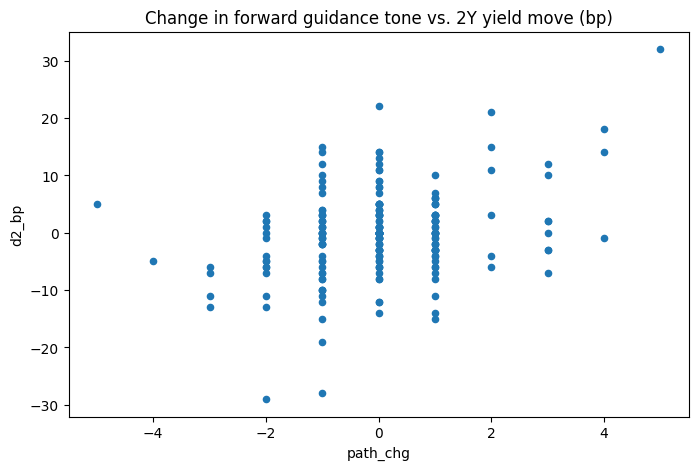

In [45]:
# Check 1: do rate changes match the headlines?
check = m[m["rate_chg_bp"] != 0][["date", "rate_chg_bp", "title"]]
print(check.tail(10).to_string())
print()

# First look: how do these move together?
cols = ["overall", "overall_chg", "path_chg", "rate_chg_bp", "d2_bp", "d5_bp"]
print(m[cols].corr().round(2))

m.plot.scatter(x="path_chg", y="d2_bp", title="Change in forward guidance tone vs. 2Y yield move (bp)", figsize=(8, 5))

In [46]:
import statsmodels.formula.api as smf

data = m.dropna(subset=["d2_bp", "d5_bp", "rate_chg_bp", "path_chg", "overall_chg"]).copy()
print("Statements in regression:", len(data))

def run(formula, df, label):
    r = smf.ols(formula, data=df).fit(cov_type="HC1")
    print(f"\n=== {label} ===   n = {int(r.nobs)},  R² = {r.rsquared:.3f}")
    print(pd.DataFrame({"coef": r.params, "p_value": r.pvalues}).round(3).to_string())
    return r

# Main tests
base  = run("d2_bp ~ rate_chg_bp",               data, "2Y: decision only")
guide = run("d2_bp ~ rate_chg_bp + path_chg",    data, "2Y: decision + forward guidance change")
over  = run("d2_bp ~ rate_chg_bp + overall_chg", data, "2Y: decision + overall tone change")
run("d5_bp ~ rate_chg_bp + path_chg",            data, "5Y: decision + forward guidance change")

# Robustness: does it survive without the crisis periods?
no_covid  = data[~data["date"].between("2020-03-01", "2020-04-30")]
no_crises = no_covid[~no_covid["date"].between("2008-09-01", "2009-06-30")]
run("d2_bp ~ rate_chg_bp + path_chg", no_covid,  "2Y: excluding Mar–Apr 2020")
run("d2_bp ~ rate_chg_bp + path_chg", no_crises, "2Y: excluding 2008–09 AND 2020 crises")

print(f"\nR² added by forward guidance: {guide.rsquared - base.rsquared:.3f}")
print(f"R² added by overall tone:     {over.rsquared - base.rsquared:.3f}")

Statements in regression: 210

=== 2Y: decision only ===   n = 210,  R² = 0.041
              coef  p_value
Intercept   -0.036    0.945
rate_chg_bp  0.069    0.014

=== 2Y: decision + forward guidance change ===   n = 210,  R² = 0.144
              coef  p_value
Intercept   -0.066    0.892
rate_chg_bp  0.066    0.013
path_chg     1.755    0.000

=== 2Y: decision + overall tone change ===   n = 210,  R² = 0.179
              coef  p_value
Intercept   -0.113    0.812
rate_chg_bp  0.050    0.063
overall_chg  2.031    0.000

=== 5Y: decision + forward guidance change ===   n = 210,  R² = 0.077
              coef  p_value
Intercept    0.189    0.682
rate_chg_bp -0.001    0.980
path_chg     1.390    0.000

=== 2Y: excluding Mar–Apr 2020 ===   n = 206,  R² = 0.136
              coef  p_value
Intercept   -0.027    0.957
rate_chg_bp  0.064    0.023
path_chg     1.730    0.000

=== 2Y: excluding 2008–09 AND 2020 crises ===   n = 198,  R² = 0.128
              coef  p_value
Intercept   -0.016    

In [47]:
# --- Part A: the "dumb" baseline — count hawkish vs. dovish words ---
HAWK = ["inflation pressure", "inflationary pressure", "excess demand", "tighten", "further increase",
        "raise", "higher interest rates", "upside risk", "strong", "robust", "overheat",
        "withdraw", "normaliz", "persistent", "entrenched", "above target"]
DOVE = ["excess supply", "slack", "downside risk", "weak", "stimulus", "accommodat",
        "lower", "cut", "reduc", "eas", "support", "below target", "deteriorat", "slow"]

def dict_score(text):
    t = str(text).lower()
    h = sum(t.count(w) for w in HAWK)
    d = sum(t.count(w) for w in DOVE)
    return 0 if h + d == 0 else (h - d) / (h + d)

m["dict"] = m["text"].apply(dict_score)
m["dict_chg"] = m["dict"].diff()

data = m.dropna(subset=["d2_bp", "rate_chg_bp", "path_chg", "overall_chg", "dict_chg"]).copy()

# Put every tone measure on the same scale (1 = one standard deviation) so they're comparable
for col in ["path_chg", "overall_chg", "dict_chg"]:
    data[col + "_z"] = (data[col] - data[col].mean()) / data[col].std()

base = smf.ols("d2_bp ~ rate_chg_bp", data=data).fit(cov_type="HC1")
print(f"Decision only: R² = {base.rsquared:.3f}\n")
print(f"{'Tone measure':<25}{'bp per 1 SD':>12}{'p-value':>10}{'R²':>8}{'R² added':>10}")
for col, name in [("dict_chg_z", "Word-count baseline"), ("path_chg_z", "LLM forward guidance"), ("overall_chg_z", "LLM overall tone")]:
    r = smf.ols(f"d2_bp ~ rate_chg_bp + {col}", data=data).fit(cov_type="HC1")
    print(f"{name:<25}{r.params[col]:>12.2f}{r.pvalues[col]:>10.3f}{r.rsquared:>8.3f}{r.rsquared - base.rsquared:>10.3f}")

# Head-to-head: put both in the same model
race = smf.ols("d2_bp ~ rate_chg_bp + path_chg_z + dict_chg_z", data=data).fit(cov_type="HC1")
print("\nHead-to-head (both in one model):")
print(pd.DataFrame({"coef": race.params, "p_value": race.pvalues}).round(3).to_string())

# --- Part B: how big is this in trading terms? ---
print(f"\nTypical forward-guidance shift (1 SD): {data['path_chg'].std():.2f} points")
print(f"Avg absolute 2Y move, announcement days: {data['d2_bp'].abs().mean():.1f} bp")
print(f"Avg absolute 2Y move, all days:          {d2.abs().mean():.1f} bp")

Decision only: R² = 0.041

Tone measure              bp per 1 SD   p-value      R²  R² added
Word-count baseline              1.62     0.000   0.087     0.046
LLM forward guidance             2.42     0.000   0.144     0.103
LLM overall tone                 2.83     0.000   0.179     0.138

Head-to-head (both in one model):
              coef  p_value
Intercept   -0.046    0.925
rate_chg_bp  0.063    0.020
path_chg_z   2.189    0.001
dict_chg_z   1.181    0.007

Typical forward-guidance shift (1 SD): 1.38 points
Avg absolute 2Y move, announcement days: 5.2 bp
Avg absolute 2Y move, all days:          3.3 bp


In [48]:
NAMES = ["Thiessen", "Dodge", "Carney", "Poloz", "Macklem", "Wilkins", "Rogers", "Mendes"]
MONTHS = r"\b(January|February|March|April|May|June|July|August|September|October|November|December)\b"

def blind(text):
    t = str(text)
    t = re.sub(MONTHS, "[MONTH]", t)
    t = re.sub(r"\[MONTH\]\s+\d{1,2}", "[MONTH] [DAY]", t)
    t = re.sub(r"\b\d{1,2}\s+\[MONTH\]", "[DAY] [MONTH]", t)
    t = re.sub(r"\b(19|20)\d{2}\b", "[YEAR]", t)
    t = re.sub(r"COVID-19|COVID|coronavirus|pandemic", "[EVENT]", t, flags=re.IGNORECASE)
    for n in NAMES:
        t = t.replace(n, "[NAME]")
    return t

print(blind(m.loc[m["date"] == "2020-03-27", "text"].iloc[0])[:600])
print("\n--- scoring blinded statements ---\n")

blind_results = []
for i, row in m.iterrows():
    try:
        s = score_statement(blind(row["text"]))
        s["date"] = row["date"]
        blind_results.append(s)
    except Exception as e:
        print("Error on", row["date"].date(), "-", e)
    if i % 20 == 0:
        print(f"{i}/{len(m)} scored")
        pd.DataFrame(blind_results).to_csv("scores_blind.csv", index=False)

blind_df = pd.DataFrame(blind_results)
blind_df.to_csv("scores_blind.csv", index=False)
print("Done:", len(blind_df))

Bank of Canada lowers overnight rate target to ¼ percent
The Bank of Canada today lowered its target for the overnight rate by 50 basis points to ¼ percent. The Bank Rate is correspondingly ½ percent and the deposit rate is ¼ percent. This unscheduled rate decision brings the policy rate to its effective lower bound and is intended to provide support to the Canadian financial system and the economy during the [EVENT] [EVENT].
The spread of [EVENT] is having serious consequences for Canadians and for the economy, as is the abrupt decline in world oil prices. The [EVENT]-driven contraction has p

--- scoring blinded statements ---

0/211 scored
20/211 scored
40/211 scored
60/211 scored
80/211 scored
100/211 scored
120/211 scored
Error on 2017-04-12 - Expecting ',' delimiter: line 1 column 134 (char 133)
140/211 scored
160/211 scored
180/211 scored
Error on 2023-03-08 - Expecting ',' delimiter: line 1 column 132 (char 131)
200/211 scored
Done: 209


In [49]:
for d in ["2017-04-12", "2023-03-08"]:
    row = m[m["date"] == d].iloc[0]
    for attempt in range(3):
        try:
            s = score_statement(blind(row["text"]))
            s["date"] = row["date"]
            blind_results.append(s)
            print(d, "OK")
            break
        except Exception as e:
            print(d, "retry", attempt + 1, "failed:", e)

blind_df = pd.DataFrame(blind_results).drop_duplicates("date").sort_values("date")
blind_df.to_csv("scores_blind.csv", index=False)
print("Total blind scores:", len(blind_df))

2017-04-12 OK
2023-03-08 OK
Total blind scores: 211


In [50]:
b = blind_df[["date", "rate_path", "overall"]].rename(columns={"rate_path": "path_blind", "overall": "overall_blind"})
mb = m.merge(b, on="date", how="left").sort_values("date").reset_index(drop=True)
mb["path_blind_chg"] = mb["path_blind"].diff()
mb["overall_blind_chg"] = mb["overall_blind"].diff()

# 1. How similar are the scores?
print("Score agreement, original vs. blind:")
print("  Forward guidance correlation:", round(mb["rate_path"].corr(mb["path_blind"]), 3))
print("  Overall tone correlation:    ", round(mb["overall"].corr(mb["overall_blind"]), 3))
print("  Identical guidance score:    ", f'{(mb["rate_path"] == mb["path_blind"]).mean():.0%} of statements')

# 2. Does the result survive blinding?
data = mb.dropna(subset=["d2_bp", "rate_chg_bp", "path_chg", "path_blind_chg", "overall_chg", "overall_blind_chg"]).copy()
calm = data[~data["date"].between("2020-03-01", "2020-04-30") & ~data["date"].between("2008-09-01", "2009-06-30")]

for sample, label in [(data, "FULL SAMPLE"), (calm, "EXCLUDING CRISES")]:
    base = smf.ols("d2_bp ~ rate_chg_bp", data=sample).fit(cov_type="HC1")
    print(f"\n{label} (n={len(sample)}) — decision only R² = {base.rsquared:.3f}")
    print(f"{'Measure':<22}{'coef':>8}{'p-value':>10}{'R²':>8}{'R² added':>10}")
    for col, name in [("path_chg", "Original guidance"), ("path_blind_chg", "Blind guidance"),
                      ("overall_chg", "Original overall"), ("overall_blind_chg", "Blind overall")]:
        r = smf.ols(f"d2_bp ~ rate_chg_bp + {col}", data=sample).fit(cov_type="HC1")
        print(f"{name:<22}{r.params[col]:>8.2f}{r.pvalues[col]:>10.3f}{r.rsquared:>8.3f}{r.rsquared - base.rsquared:>10.3f}")

mb.drop(columns=["text"]).to_csv("master.csv", index=False)

Score agreement, original vs. blind:
  Forward guidance correlation: 0.951
  Overall tone correlation:     0.954
  Identical guidance score:     63% of statements

FULL SAMPLE (n=210) — decision only R² = 0.041
Measure                   coef   p-value      R²  R² added
Original guidance         1.75     0.000   0.144     0.103
Blind guidance            1.71     0.000   0.144     0.103
Original overall          2.03     0.000   0.179     0.138
Blind overall             1.91     0.000   0.176     0.135

EXCLUDING CRISES (n=198) — decision only R² = 0.028
Measure                   coef   p-value      R²  R² added
Original guidance         1.72     0.001   0.128     0.100
Blind guidance            1.75     0.000   0.135     0.107
Original overall          2.07     0.000   0.171     0.143
Blind overall             1.95     0.000   0.169     0.141


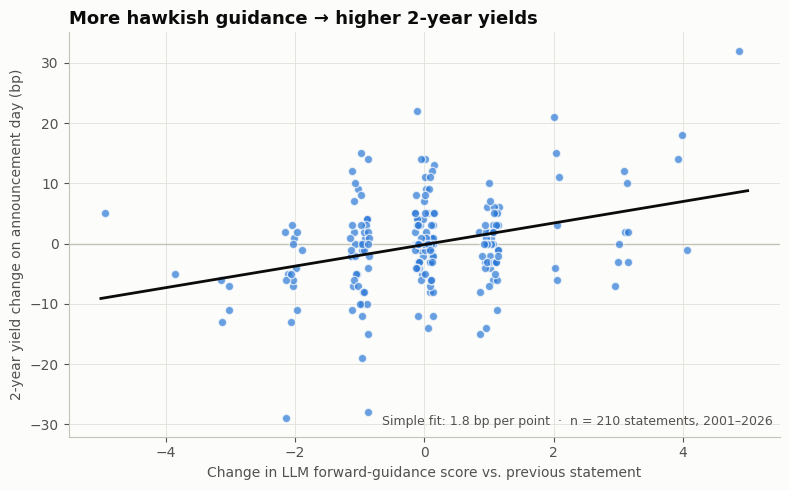

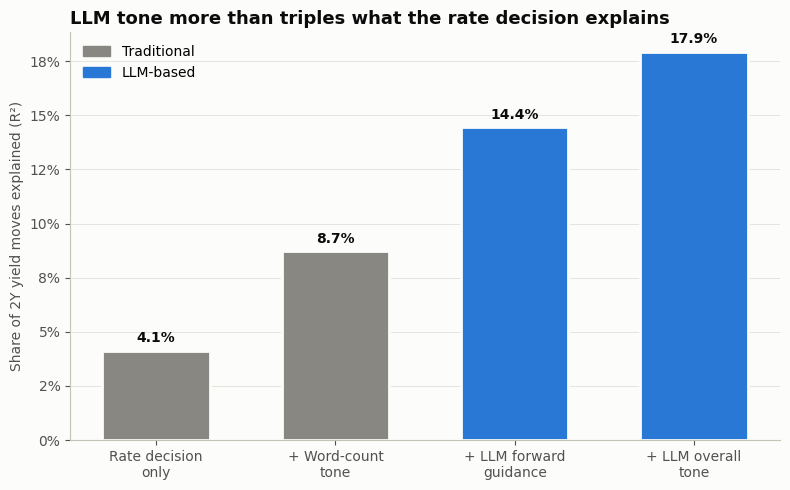

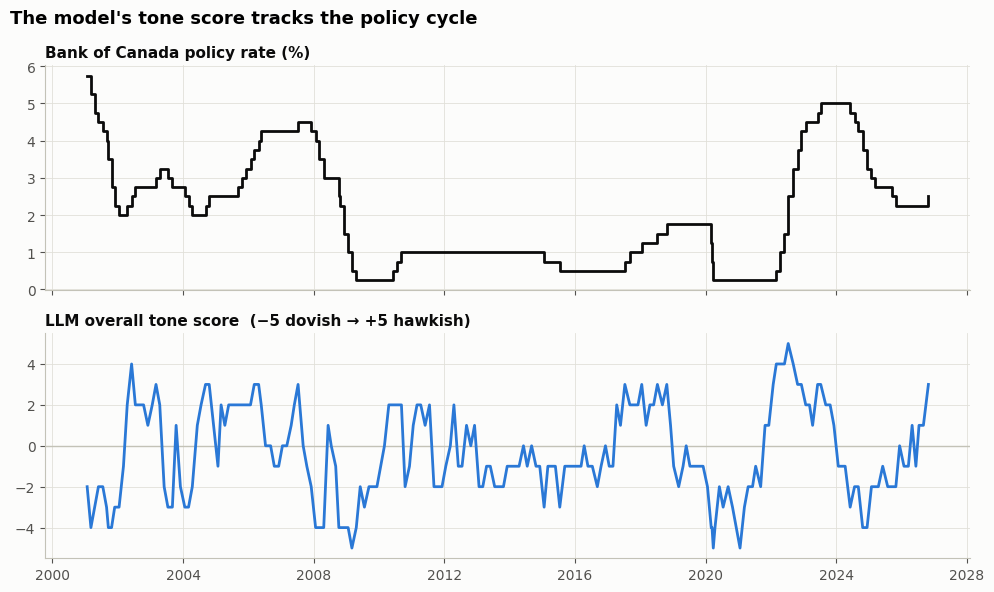

In [51]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

BLUE, GRAY = "#2a78d6", "#898781"
INK, INK2, GRID, AXIS, BG = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlecolor": INK, "font.size": 10,
})

d = mb.dropna(subset=["d2_bp", "rate_chg_bp", "path_chg", "overall_chg", "dict_chg"]).copy()

# ---------- Chart 1: the core relationship ----------
rng = np.random.default_rng(0)
x = d["path_chg"] + rng.uniform(-0.15, 0.15, len(d))   # small jitter so stacked dots are visible
fit = np.polyfit(d["path_chg"], d["d2_bp"], 1)
xs = np.linspace(d["path_chg"].min(), d["path_chg"].max(), 50)

fig, ax = plt.subplots(figsize=(8, 5))
ax.axhline(0, color=AXIS, lw=1, zorder=1)
ax.scatter(x, d["d2_bp"], s=36, color=BLUE, alpha=0.7, edgecolor=BG, linewidth=1, zorder=2)
ax.plot(xs, np.polyval(fit, xs), color=INK, lw=2, zorder=3)
ax.set_title("More hawkish guidance → higher 2-year yields", loc="left")
ax.set_xlabel("Change in LLM forward-guidance score vs. previous statement")
ax.set_ylabel("2-year yield change on announcement day (bp)")
ax.text(0.99, 0.03, f"Simple fit: {fit[0]:.1f} bp per point  ·  n = {len(d)} statements, 2001–2026",
        transform=ax.transAxes, ha="right", color=INK2, fontsize=9)
fig.tight_layout(); fig.savefig("chart1_scatter.png", dpi=200); plt.show()

# ---------- Chart 2: what each method explains ----------
specs = [("Rate decision\nonly",        "d2_bp ~ rate_chg_bp",               GRAY),
         ("+ Word-count\ntone",         "d2_bp ~ rate_chg_bp + dict_chg",    GRAY),
         ("+ LLM forward\nguidance",    "d2_bp ~ rate_chg_bp + path_chg",    BLUE),
         ("+ LLM overall\ntone",        "d2_bp ~ rate_chg_bp + overall_chg", BLUE)]
labels = [s[0] for s in specs]
r2 = [smf.ols(f, data=d).fit().rsquared for _, f, _ in specs]
colors = [s[2] for s in specs]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, r2, color=colors, width=0.6, edgecolor=BG, linewidth=2)
for b, v in zip(bars, r2):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.004, f"{v:.1%}", ha="center", color=INK, fontweight="bold")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("Share of 2Y yield moves explained (R²)")
ax.set_title("LLM tone more than triples what the rate decision explains", loc="left")
ax.legend(handles=[mpatches.Patch(color=GRAY, label="Traditional"), mpatches.Patch(color=BLUE, label="LLM-based")],
          frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig("chart2_r2.png", dpi=200); plt.show()

# ---------- Chart 3: tone vs. the policy cycle (two panels, one y-axis each) ----------
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.step(mb["date"], mb["rate_final"], where="post", color=INK, lw=2)
a1.set_title("Bank of Canada policy rate (%)", loc="left", fontsize=11)
a2.axhline(0, color=AXIS, lw=1)
a2.plot(mb["date"], mb["overall"], color=BLUE, lw=2)
a2.set_title("LLM overall tone score  (−5 dovish → +5 hawkish)", loc="left", fontsize=11)
fig.suptitle("The model's tone score tracks the policy cycle", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout(); fig.savefig("chart3_cycle.png", dpi=200); plt.show()

In [52]:
print(d.loc[d["d2_bp"].idxmax(), ["date", "title", "path_chg", "d2_bp"]])
print(d.loc[d["path_chg"].idxmin(), ["date", "title", "path_chg", "d2_bp"]])

date                                      2008-06-10 00:00:00
title       Bank of Canada keeps overnight rate target at ...
path_chg                                                  5.0
d2_bp                                                    32.0
Name: 60, dtype: object
date                                      2011-09-07 00:00:00
title       Bank of Canada maintains overnight rate target...
path_chg                                                 -5.0
d2_bp                                                     5.0
Name: 87, dtype: object


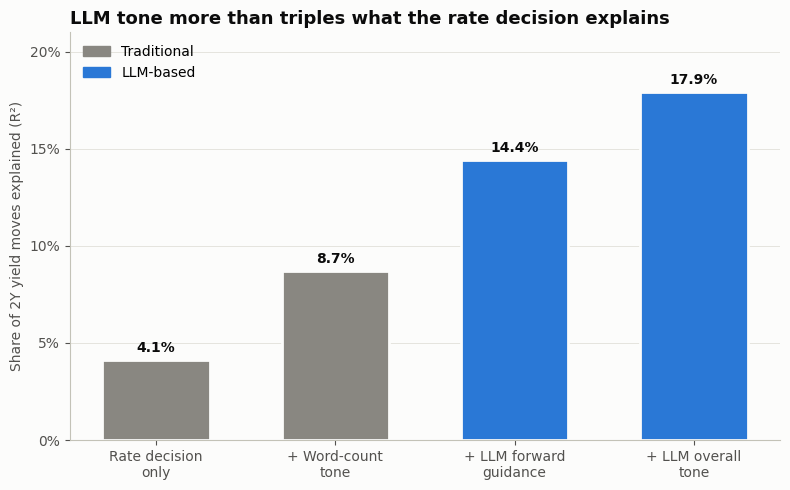

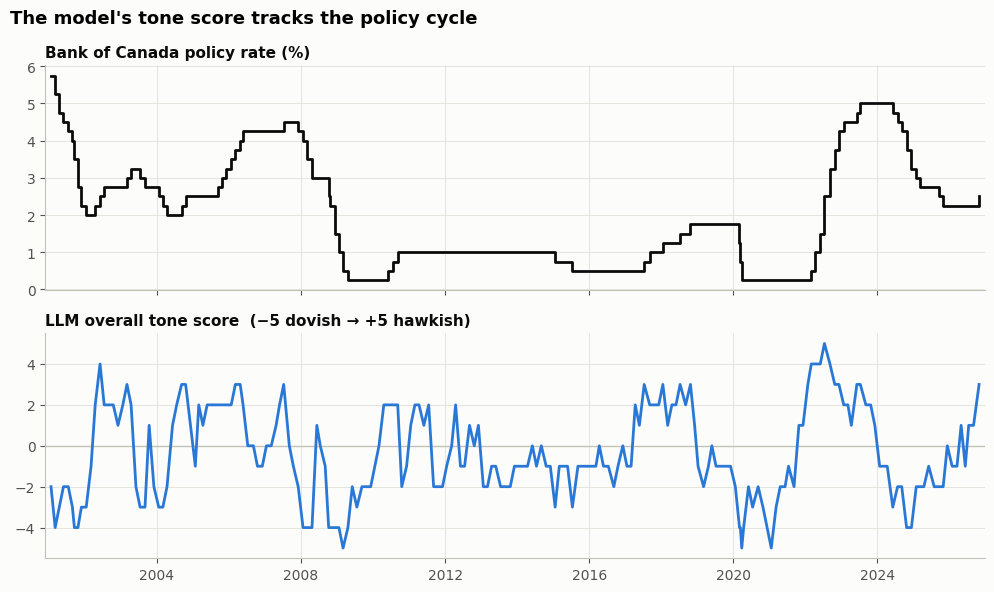

In [53]:
from matplotlib.ticker import MultipleLocator, PercentFormatter

# Chart 2: clean 5% ticks
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, r2, color=colors, width=0.6, edgecolor=BG, linewidth=2)
for b, v in zip(bars, r2):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.004, f"{v:.1%}", ha="center", color=INK, fontweight="bold")
ax.yaxis.set_major_locator(MultipleLocator(0.05))
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 0.21)
ax.set_ylabel("Share of 2Y yield moves explained (R²)")
ax.set_title("LLM tone more than triples what the rate decision explains", loc="left")
ax.legend(handles=[mpatches.Patch(color=GRAY, label="Traditional"), mpatches.Patch(color=BLUE, label="LLM-based")],
          frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig("chart2_r2.png", dpi=200); plt.show()

# Chart 3: x-axis ends with the data
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
a1.step(mb["date"], mb["rate_final"], where="post", color=INK, lw=2)
a1.set_title("Bank of Canada policy rate (%)", loc="left", fontsize=11)
a2.axhline(0, color=AXIS, lw=1)
a2.plot(mb["date"], mb["overall"], color=BLUE, lw=2)
a2.set_title("LLM overall tone score  (−5 dovish → +5 hawkish)", loc="left", fontsize=11)
a2.set_xlim(mb["date"].min() - pd.Timedelta(days=60), mb["date"].max() + pd.Timedelta(days=60))
fig.suptitle("The model's tone score tracks the policy cycle", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout(); fig.savefig("chart3_cycle.png", dpi=200); plt.show()